In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency
from scipy import stats



In [2]:
df = pd.read_csv("../../../datasets/amz_uk_price_prediction_dataset.csv")

In [3]:
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


### Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: Understand the relationship between product categories and their best-seller status.

1. **Crosstab Analysis**:
    - Create a crosstab between the product `category` and the `isBestSeller` status.
    
    - Are there categories where being a best-seller is more prevalent? 
    	
    	*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*


2. **Statistical Tests**:
    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    - Compute Cramér's V to understand the strength of association between best-seller status and category.

3. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

In [4]:
ct = pd.crosstab(df["category"], df["isBestSeller"])
ct.head()



isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3


In [5]:
best_seller_rate = ct[True] / ct.sum(axis=1)
best_seller_rate.sort_values(ascending=False).head(10)



category
Grocery                           0.058135
Smart Home Security & Lighting    0.057692
Health & Personal Care            0.057686
Mobile Phone Accessories          0.042471
Power & Hand Tools                0.035339
Billiard, Snooker & Pool          0.032129
Pet Supplies                      0.030200
Home Brewing & Wine Making        0.028455
Wind Instruments                  0.028000
Mirrors                           0.028000
dtype: float64

___
Question:
Are there categories where being a best-seller is more prevalent?

Answer:
Yes. Best-seller status is most prevalent in the Grocery category (≈5.8%), followed by Smart Home Security & Lighting and Health & Personal Care, indicating that best-sellers are more common in these categories than in others.
___

In [6]:
result = chi2_contingency(ct)
result


Chi2ContingencyResult(statistic=36540.20270061387, pvalue=0.0, dof=295, expected_freq=array([[2.47190130e+02, 8.09870149e-01],
       [4.05371878e+03, 1.32812173e+01],
       [2.49183599e+02, 8.16401360e-01],
       [1.69145827e+03, 5.54173243e+00],
       [2.53170536e+02, 8.29463782e-01],
       [8.50214439e+03, 2.78556144e+01],
       [1.06650580e+02, 3.49419782e-01],
       [2.57157474e+02, 8.42526204e-01],
       [9.51781673e+03, 3.11832664e+01],
       [1.50008526e+04, 4.91473619e+01],
       [9.32544700e+03, 3.05530045e+01],
       [2.38219520e+02, 7.80479700e-01],
       [3.22941944e+03, 1.05805616e+01],
       [9.44704859e+03, 3.09514084e+01],
       [6.68808779e+03, 2.19122125e+01],
       [5.26275760e+02, 1.72423967e+00],
       [1.90296531e+04, 6.23469391e+01],
       [2.77191835e+03, 9.08164873e+00],
       [2.53170536e+02, 8.29463782e-01],
       [4.04674164e+02, 1.32583581e+00],
       [1.92489346e+04, 6.30653723e+01],
       [3.10482764e+03, 1.01723609e+01],
       [2.04

In [7]:
chi2, p, dof, expected = result


In [ ]:
p
expected[:5]


array([[2.47190130e+02, 8.09870149e-01],
       [4.05371878e+03, 1.32812173e+01],
       [2.49183599e+02, 8.16401360e-01],
       [1.69145827e+03, 5.54173243e+00],
       [2.53170536e+02, 8.29463782e-01]])

In [9]:
chi2, p, dof, expected = chi2_contingency(ct)

print("chi2:", chi2)
print("p:", p)
print("dof:", dof)
print("expected min:", expected.min())
print("expected max:", expected.max())

chi2: 36540.20270061387
p: 0.0
dof: 295
expected min: 0.17634269378074038
expected max: 833534.0884663973


In [ ]:
# How to read it
# p is the only number you use for “significant or not”:
# if p < 0.05 → association exists (category and best-seller are not independent)
# if p >= 0.05 → no evidence of association
# expected min matters because:
# if many expected counts are < 5, the chi-square assumptions are shaky (common here because “True” is rare across many categories)

# so there is a relationship. (acourding to the p) but the chi-square is shaky?

In [11]:
n = ct.to_numpy().sum()
r, k = ct.shape
cramers_v = np.sqrt(chi2 / (n * (min(r - 1, k - 1))))

cramers_v

0.1222829439760564

In [ ]:
# How to interpret Cramér’s V (simple)
# ~0.00–0.10: weak
#~0.10–0.30: moderate
# 0.30: strong

# so there is a weak relationship between category and best-seller status?

In [13]:
n


2443651

In [14]:
ct.shape


(296, 2)

In [15]:
min(r - 1, k - 1)


1

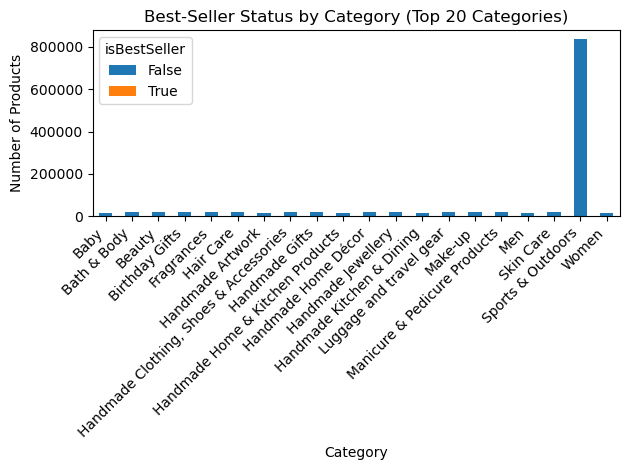

In [16]:
top20 = df["category"].value_counts().head(20).index

ct_top20 = pd.crosstab(
    df.loc[df["category"].isin(top20), "category"],
    df.loc[df["category"].isin(top20), "isBestSeller"]
)

ct_top20.plot(kind="bar", stacked=True)
plt.title("Best-Seller Status by Category (Top 20 Categories)")
plt.xlabel("Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


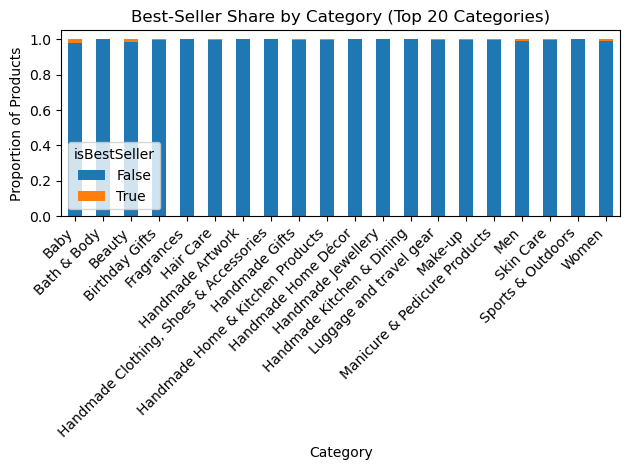

In [17]:
ct_top20_pct = ct_top20.div(ct_top20.sum(axis=1), axis=0)

ct_top20_pct.plot(kind="bar", stacked=True)
plt.title("Best-Seller Share by Category (Top 20 Categories)")
plt.xlabel("Category")
plt.ylabel("Proportion of Products")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*

1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.

2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.

3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.


In [18]:
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_no_outliers = df[(df["price"] >= lower_bound) & (df["price"] <= upper_bound)].copy()

print("Original rows:", df.shape[0])
print("After removing outliers:", df_no_outliers.shape[0])
print("Removed rows:", df.shape[0] - df_no_outliers.shape[0])

lower_bound, upper_bound


Original rows: 2443651
After removing outliers: 2115963
Removed rows: 327688


(-44.01, 99.99000000000001)

In [19]:
df["price"].describe()
df_no_outliers["price"].describe()


count    2.115963e+06
mean     2.340827e+01
std      2.051335e+01
min      0.000000e+00
25%      9.130000e+00
50%      1.599000e+01
75%      2.999000e+01
max      9.999000e+01
Name: price, dtype: float64

In [20]:
top20_categories = df_no_outliers["category"].value_counts().head(20).index
top20_categories


Index(['Sports & Outdoors', 'Beauty', 'Bath & Body',
       'Manicure & Pedicure Products',
       'Handmade Clothing, Shoes & Accessories', 'Make-up', 'Skin Care',
       'Hair Care', 'Birthday Gifts', 'Handmade Gifts', 'Handmade Home Décor',
       'Luggage and travel gear', 'Women', 'Fragrances',
       'Handmade Kitchen & Dining', 'Handmade Artwork',
       'Handmade Home & Kitchen Products', 'Handmade Jewellery', 'Men',
       'Baby'],
      dtype='object')

In [21]:
df_top20=df_no_outliers[df_no_outliers["category"].isin(top20_categories)].copy()
df_top20.shape

(1033008, 9)

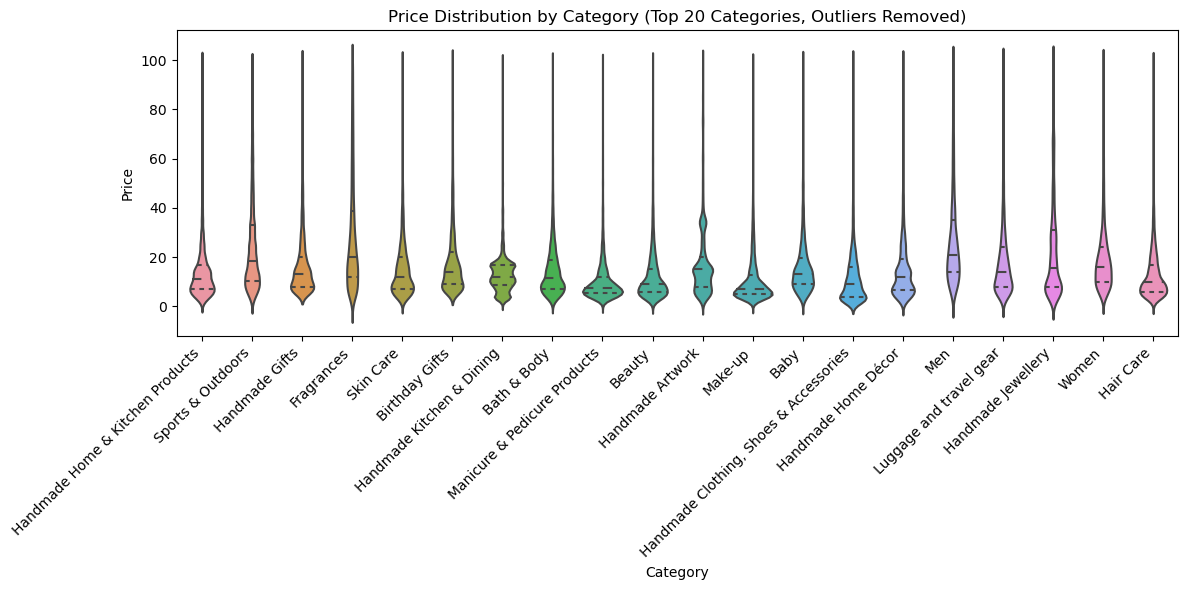

In [22]:
plt.figure(figsize=(12, 6))
sns.violinplot(data=df_top20, x="category", y="price", inner="quartile")
plt.title("Price Distribution by Category (Top 20 Categories, Outliers Removed)")
plt.xlabel("Category")
plt.ylabel("Price")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [23]:
median_price_by_category = df_no_outliers.groupby("category")["price"].median().sort_values(ascending=False)
median_price_by_category.head(10)



category
Desktop PCs               74.00
Boxing Shoes              69.79
Tablets                   69.00
Graphics Cards            68.54
Motherboards              67.92
Made in Italy Handmade    64.00
Digital Frames            63.90
Streaming Clients         62.68
Golf Shoes                62.39
Ski Helmets               61.33
Name: price, dtype: float64

___
Question:
Which product category tends to have the highest median price? Don't filter here by top categories.

Answer:
Desktop PCs had the highest median.
____

In [24]:
top10_categories = df_no_outliers["category"].value_counts().head(10).index
top10_categories


Index(['Sports & Outdoors', 'Beauty', 'Bath & Body',
       'Manicure & Pedicure Products',
       'Handmade Clothing, Shoes & Accessories', 'Make-up', 'Skin Care',
       'Hair Care', 'Birthday Gifts', 'Handmade Gifts'],
      dtype='object')

In [25]:
avg_price_top10 = (
    df_no_outliers[df_no_outliers["category"].isin(top10_categories)]
    .groupby("category")["price"]
    .mean()
    .sort_values(ascending=False)
)

avg_price_top10


category
Sports & Outdoors                         25.172065
Birthday Gifts                            18.600195
Handmade Gifts                            17.395112
Skin Care                                 15.654722
Bath & Body                               14.678683
Hair Care                                 13.461408
Handmade Clothing, Shoes & Accessories    12.958639
Beauty                                    12.523480
Make-up                                   10.612918
Manicure & Pedicure Products              10.231825
Name: price, dtype: float64

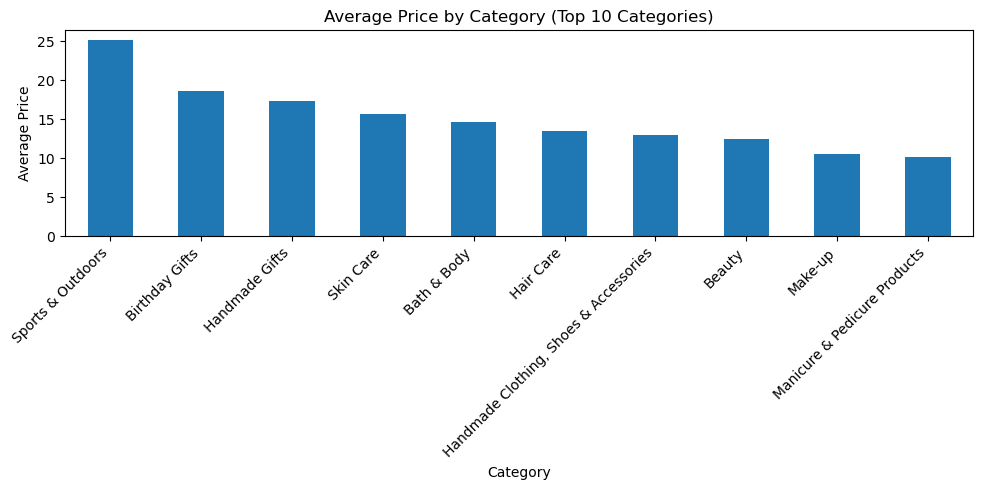

In [26]:
avg_price_top10.plot(kind="bar", figsize=(10, 5))
plt.title("Average Price by Category (Top 10 Categories)")
plt.xlabel("Category")
plt.ylabel("Average Price")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [27]:
avg_price_by_category = (
    df_no_outliers.groupby("category")["price"]
    .mean()
    .sort_values(ascending=False)
)

avg_price_by_category.head(10)


category
Motherboards         68.772432
Boxing Shoes         67.417803
Desktop PCs          66.915562
Tablets              66.552971
Graphics Cards       65.103509
Digital Frames       60.745129
Streaming Clients    60.241803
Hockey Shoes         60.094796
Computer Cases       58.339884
Skiing Poles         57.867770
Name: price, dtype: float64

In [28]:
category_counts = df_no_outliers["category"].value_counts()

avg_price_full = avg_price_by_category.to_frame("avg_price").join(
    category_counts.rename("n_products")
)

avg_price_full.head(10)


,avg_price,n_products
category,,
Motherboards,68.772432,74
Boxing Shoes,67.417803,3873
Desktop PCs,66.915562,169
Tablets,66.552971,4638
Graphics Cards,65.103509,57
Digital Frames,60.745129,310
Streaming Clients,60.241803,1692
Hockey Shoes,60.094796,221
Computer Cases,58.339884,173


___
Question:
Which product category commands the highest average price? Don't filter here by top categories.

Answer:
Motherboards show the highest average price overall, although categories such as Boxing Shoes and Tablets also show high average prices with a much larger product counts.
___

In [29]:
top10_categories = df_no_outliers["category"].value_counts().head(10).index
top10_categories


Index(['Sports & Outdoors', 'Beauty', 'Bath & Body',
       'Manicure & Pedicure Products',
       'Handmade Clothing, Shoes & Accessories', 'Make-up', 'Skin Care',
       'Hair Care', 'Birthday Gifts', 'Handmade Gifts'],
      dtype='object')

In [30]:
df_top10 = df_no_outliers[df_no_outliers["category"].isin(top10_categories)].copy()
df_top10.shape


(862465, 9)

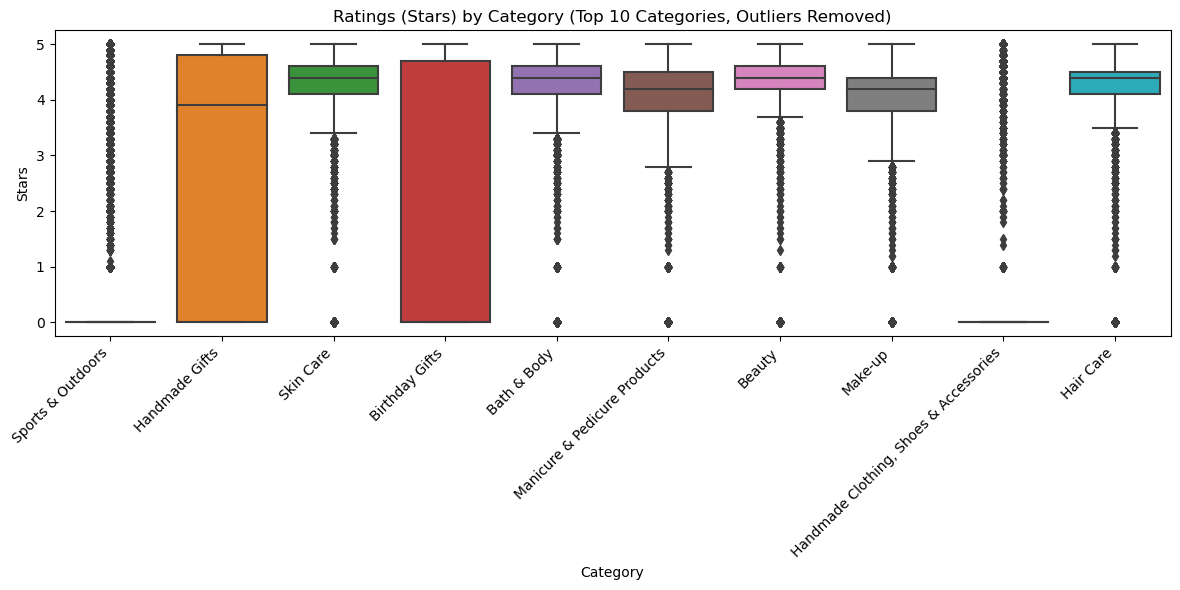

In [32]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_top10, x="category", y="stars")
plt.title("Ratings (Stars) by Category (Top 10 Categories, Outliers Removed)")
plt.xlabel("Category")
plt.ylabel("Stars")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [33]:
median_stars_by_category = (
    df_no_outliers.groupby("category")["stars"]
    .median()
    .sort_values(ascending=False)
)

median_stars_by_category.head(10)


category
Computer Memory                 4.7
Building & Construction Toys    4.6
Office Paper Products           4.6
Luxury Food & Drink             4.6
Kids' Play Figures              4.6
Hobbies                         4.6
Beer, Wine & Spirits            4.6
Laptop Accessories              4.6
Cables & Accessories            4.5
CPUs                            4.5
Name: stars, dtype: float64

In [34]:
category_counts = df_no_outliers["category"].value_counts()

median_stars_full = median_stars_by_category.to_frame("median_stars").join(
    category_counts.rename("n_products")
)

median_stars_full.head(10)


,median_stars,n_products
category,,
Computer Memory,4.7,211
Building & Construction Toys,4.6,8685
Office Paper Products,4.6,9090
Luxury Food & Drink,4.6,657
Kids' Play Figures,4.6,9377
Hobbies,4.6,9065
"Beer, Wine & Spirits",4.6,9271
Laptop Accessories,4.6,250
Cables & Accessories,4.5,9031


___
Question:
Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

Answer:
Computer Memory has the highest median customer rating (4.7 stars), but the median ratings are consistently high across most categories
___

### Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.

1. **Correlation Coefficients**:
    - Calculate the correlation coefficient between `price` and `stars`.
    - Is there a significant correlation between product price and its rating?
	
2. **Visualizations**:
    - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
    - Use a correlation heatmap to visualize correlations between all numerical variables.
    - Examine if product prices typically follow a normal distribution using a QQ plot. 


In [36]:
pearson_corr = df_no_outliers["price"].corr(df_no_outliers["stars"])
pearson_corr

-0.07767299878181444

In [ ]:
# How to interpret Pearson (keep it simple)
# Close to 0 → little/no linear relationship
# Positive → higher price tends to relate to higher stars
# Negative → higher price tends to relate to lower stars

# so little to no linear relationship between price and stars
# negative higher price  tends to relate to lower stars


___
Question:
Is there a significant correlation between product price and its rating?

Answer:
The Pearson correlation between product price and rating is very weak and slightly negative (r ≈ −0.08), indicating that price has little to no meaningful association with customer ratings.
___

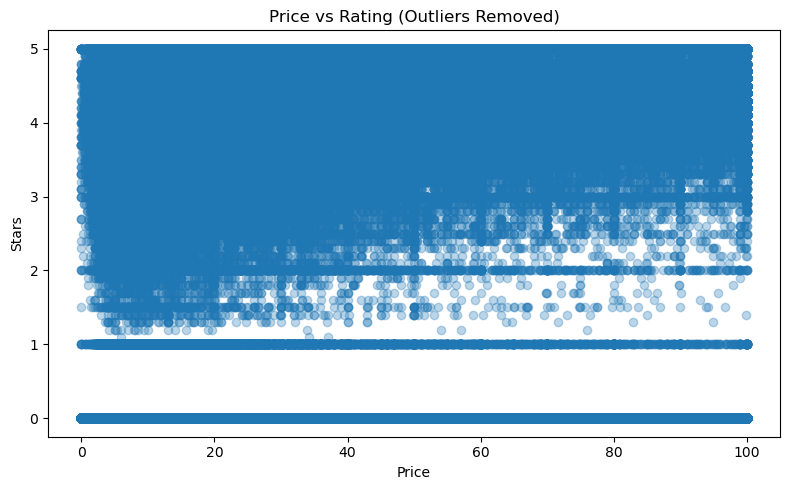

In [37]:
plt.figure(figsize=(8, 5))
plt.scatter(df_no_outliers["price"], df_no_outliers["stars"], alpha=0.3)
plt.xlabel("Price")
plt.ylabel("Stars")
plt.title("Price vs Rating (Outliers Removed)")
plt.tight_layout()
plt.show()


___
Question:
What patterns can you observe?

Answer:
- To many points
- straight lines on (atleats) the ratings of 0, 1 and 2. 
- To much clutter to really read it.
___

In [38]:
num_df = df_no_outliers.select_dtypes(include="number")
num_df.columns


Index(['uid', 'stars', 'reviews', 'price', 'boughtInLastMonth'], dtype='object')

In [39]:
corr_matrix = num_df.corr()
corr_matrix


,uid,stars,reviews,price,boughtInLastMonth
uid,1.000000,0.030288,0.020236,0.001717,0.017116
stars,0.030288,1.000000,0.083920,-0.077673,0.113994
reviews,0.020236,0.083920,1.000000,-0.008498,0.105624
price,0.001717,-0.077673,-0.008498,1.000000,-0.059051
boughtInLastMonth,0.017116,0.113994,0.105624,-0.059051,1.000000


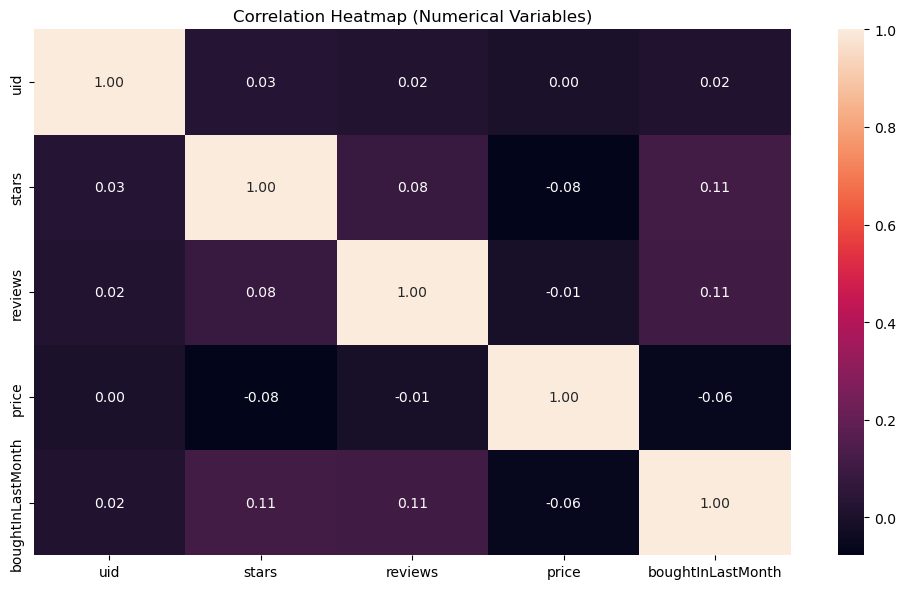

In [40]:
plt.figure(figsize=(10, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f")
plt.title("Correlation Heatmap (Numerical Variables)")
plt.tight_layout()
plt.show()

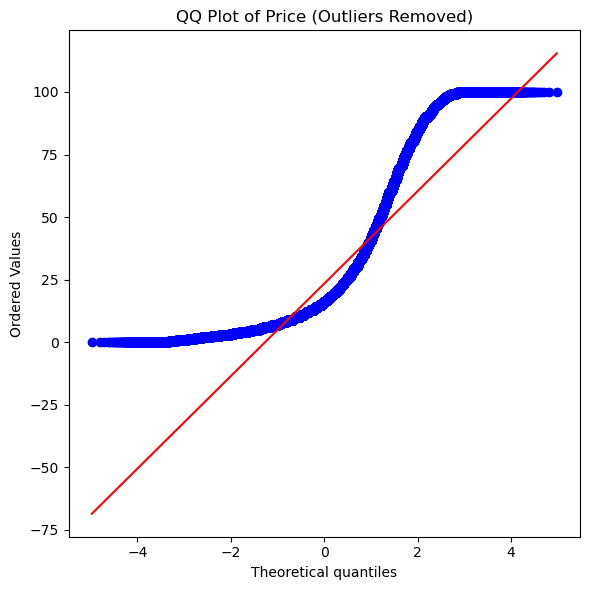

In [41]:
plt.figure(figsize=(6, 6))
stats.probplot(df_no_outliers["price"], dist="norm", plot=plt)
plt.title("QQ Plot of Price (Outliers Removed)")
plt.tight_layout()
plt.show()
